# Stage 2: Does Feature Selection Add Value?

**Leyao Chang | Factor selection follow-up**

Compare the two frozen 16-factor choices with random groups of the same size, then remove each selected factor and refit the model.

**Reused:** the original 22 inputs, 80 generated formulas (78 eligible), selected lists and 64 frozen random groups. Logistic Regression (LR) random-group scores already existed.

**Added:** matched Random Forest (RF) random-group tests, 16 deletion refits for each model, and analysis of both fixed historical windows. No new factors or API calls.

## Step 1: Fixed inputs and fair comparisons

The model settings and chosen factors stay fixed. Both later windows use 2025 January-June training. A signal's next-day answer must stay inside its own partition. These historical dates had been inspected before; this is not a new blind test.

ROC AUC is the area under the receiver operating characteristic curve. It measures how well up days rank above not-up days. It is different from prediction accuracy.

The saved experiment and an independent fresh-model replay are complete. This cell runs the offline pipeline using its checked model caches. The `--replay` command in the README refits all models.

In [1]:
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
from html import escape
import inspect
import sys
import pandas as pd
from IPython.display import display, HTML, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'Factor_Selection_80' / 'Ablation_Study' / 'run_ablation.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the unzipped FactorSelectionResearch project folder.')
STUDY = ROOT / 'Factor_Selection_80' / 'Ablation_Study'
sys.path.insert(0, str(STUDY))
import run_ablation as study
import presentation_report as report

log = StringIO()
with redirect_stdout(log):
    study.run(workers=4)
    report.build()
plan = study.read(STUDY / 'STUDY_PLAN.json')
tables = report.load_tables()
RESULTS = STUDY / 'results'
print('Completed: 166 configurations, 332 fitted estimators, two fixed 63-day windows.')
print('The saved run is verified. No API calls are sent.')

def show_table(frame, digits=5):
    html = frame.to_html(index=False, escape=True, border=0,
                         float_format=lambda number: f'{number:.{digits}f}')
    display(HTML('<style>.ablation-table table{border-collapse:collapse;width:100%;table-layout:auto;font-size:13px;}'
                 '.ablation-table th,.ablation-table td{padding:7px 9px;border-bottom:1px solid #ddd;'
                 'text-align:left;vertical-align:top;white-space:normal;overflow-wrap:anywhere;max-width:350px;}'
                 '.ablation-table th{background:#edf4f5;}</style>'
                 '<div class="ablation-table">' + html + '</div>'))

Completed: 166 configurations, 332 fitted estimators, two fixed 63-day windows.
The saved run is verified. No API calls are sent.


In [2]:
settings = pd.DataFrame([
    ['Prediction target', 'Apple next-trading-day close higher than today'],
    ['Shared original inputs', '22'],
    ['Frozen generated pool', '80 formulas; 78 eligible after the earlier duplicate screen'],
    ['Selected additions', '16 for each model; four factor names shared'],
    ['Matched random control', 'All 64 previously frozen 16-factor groups, used with both models'],
    ['Deletion experiment', 'Remove each selected addition separately and refit; keep all original 22'],
    ['Primary score', 'ROC AUC: higher is better; 0.5 is chance-level ranking'],
    ['Model settings', 'Same LR and RF recipes as the previous demo; RF averages seeds 0, 1 and 2'],
], columns=['Item', 'Setting'])
show_table(settings)
show_table(tables['date_boundaries'].rename(columns={
    'partition':'Partition', 'rows':'Examples', 'first_signal':'First signal', 'last_signal':'Last signal',
    'first_target':'First answer', 'last_target':'Last answer'}))

Item,Setting
Prediction target,Apple next-trading-day close higher than today
Shared original inputs,22
Frozen generated pool,80 formulas; 78 eligible after the earlier duplicate screen
Selected additions,16 for each model; four factor names shared
Matched random control,"All 64 previously frozen 16-factor groups, used with both models"
Deletion experiment,Remove each selected addition separately and refit; keep all original 22
Primary score,ROC AUC: higher is better; 0.5 is chance-level ranking
Model settings,"Same LR and RF recipes as the previous demo; RF averages seeds 0, 1 and 2"


Partition,Examples,First signal,Last signal,First answer,Last answer
training,121,2025-01-02,2025-06-27,2025-01-03,2025-06-30
2025_Q3,63,2025-07-01,2025-09-29,2025-07-02,2025-09-30
2025_Q4,63,2025-10-01,2025-12-30,2025-10-02,2025-12-31


In [3]:
selected = pd.DataFrame({report.MODEL_NAMES[model]: names for model, names in plan['selected_factors'].items()})
selected.insert(0, 'Position', range(1, 17))
show_table(selected)

Position,Logistic Regression,Random Forest
1,r2_intraday_body_vs_overnight_move,r2_volume_weighted_range_position_10d
2,r2_prior_body_share_of_range,r2_peer_relative_volume_nvidia
3,r2_signed_overnight_gap_range_share,r2_relative_dollar_activity_short_long
4,r2_peer_sign_consensus,r2_nonoverlapping_three_day_return_change
5,r2_prior_close_range_position,r2_volume_regime_gap
6,r2_prior_body_signed_range_fraction,r2_prior_close_range_position
7,r2_volume_acceleration_body_5d,r2_prior_range_width_scaled
8,r2_adjacent_return_sign_persistence_3d,r2_prior_close_to_low_scaled
9,r2_close_location_range_change,r2_aapl_peer_return_gap_3d
10,r2_peer_return_sign_spread_3d,r2_prior_body_share_of_range


## Step 2: Selected 16 versus random 16

Every random group has 16 distinct additions from the same 78 eligible candidates. The same 64 groups are used with both models. Their identities were frozen in the previous project, so no group is chosen or dropped because of its later score.

Below is the actual model-fitting function. It fits the same training recipe, then predicts both later windows. LR uses one fixed seed; RF uses the mean predictions from three fixed seeds.

In [4]:
print(inspect.getsource(study.fit_configuration))

def fit_configuration(config, train, tests):
    """Refit only on Q1-Q2, then predict both fixed later windows."""
    columns = ex.BASE + config["names"]
    evaluation = pd.concat([tests[p] for p in PERIODS], ignore_index=True)
    if config["model"] == "LR":
        fitted = ex.fit_lr(train, columns)
        seed_probabilities = {"42": fitted.predict_proba(evaluation[columns])[:, 1].tolist()}
    else:
        seed_probabilities = {}
        for seed in RF_SEEDS:
            fitted = shared.forest(seed).fit(train[columns], train[ex.TARGET])
            seed_probabilities[str(seed)] = fitted.predict_proba(evaluation[columns])[:, 1].tolist()
    probability = np.mean(list(seed_probabilities.values()), axis=0)
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    return {"model": config["model"], "config_id": config["config_id"],
            "seed_probabilities": seed_probabilities, "probability": probability.tolist()}



Window,Model,Selected AUC,Random mean AUC,Random groups below,Ties,Random groups above
2025_Q3,Logistic Regression,0.66970,0.59378,62,0,2
2025_Q3,Random Forest,0.53636,0.50657,49,1,14
2025_Q4,Logistic Regression,0.53980,0.49469,45,1,18
2025_Q4,Random Forest,0.47959,0.49410,27,0,37


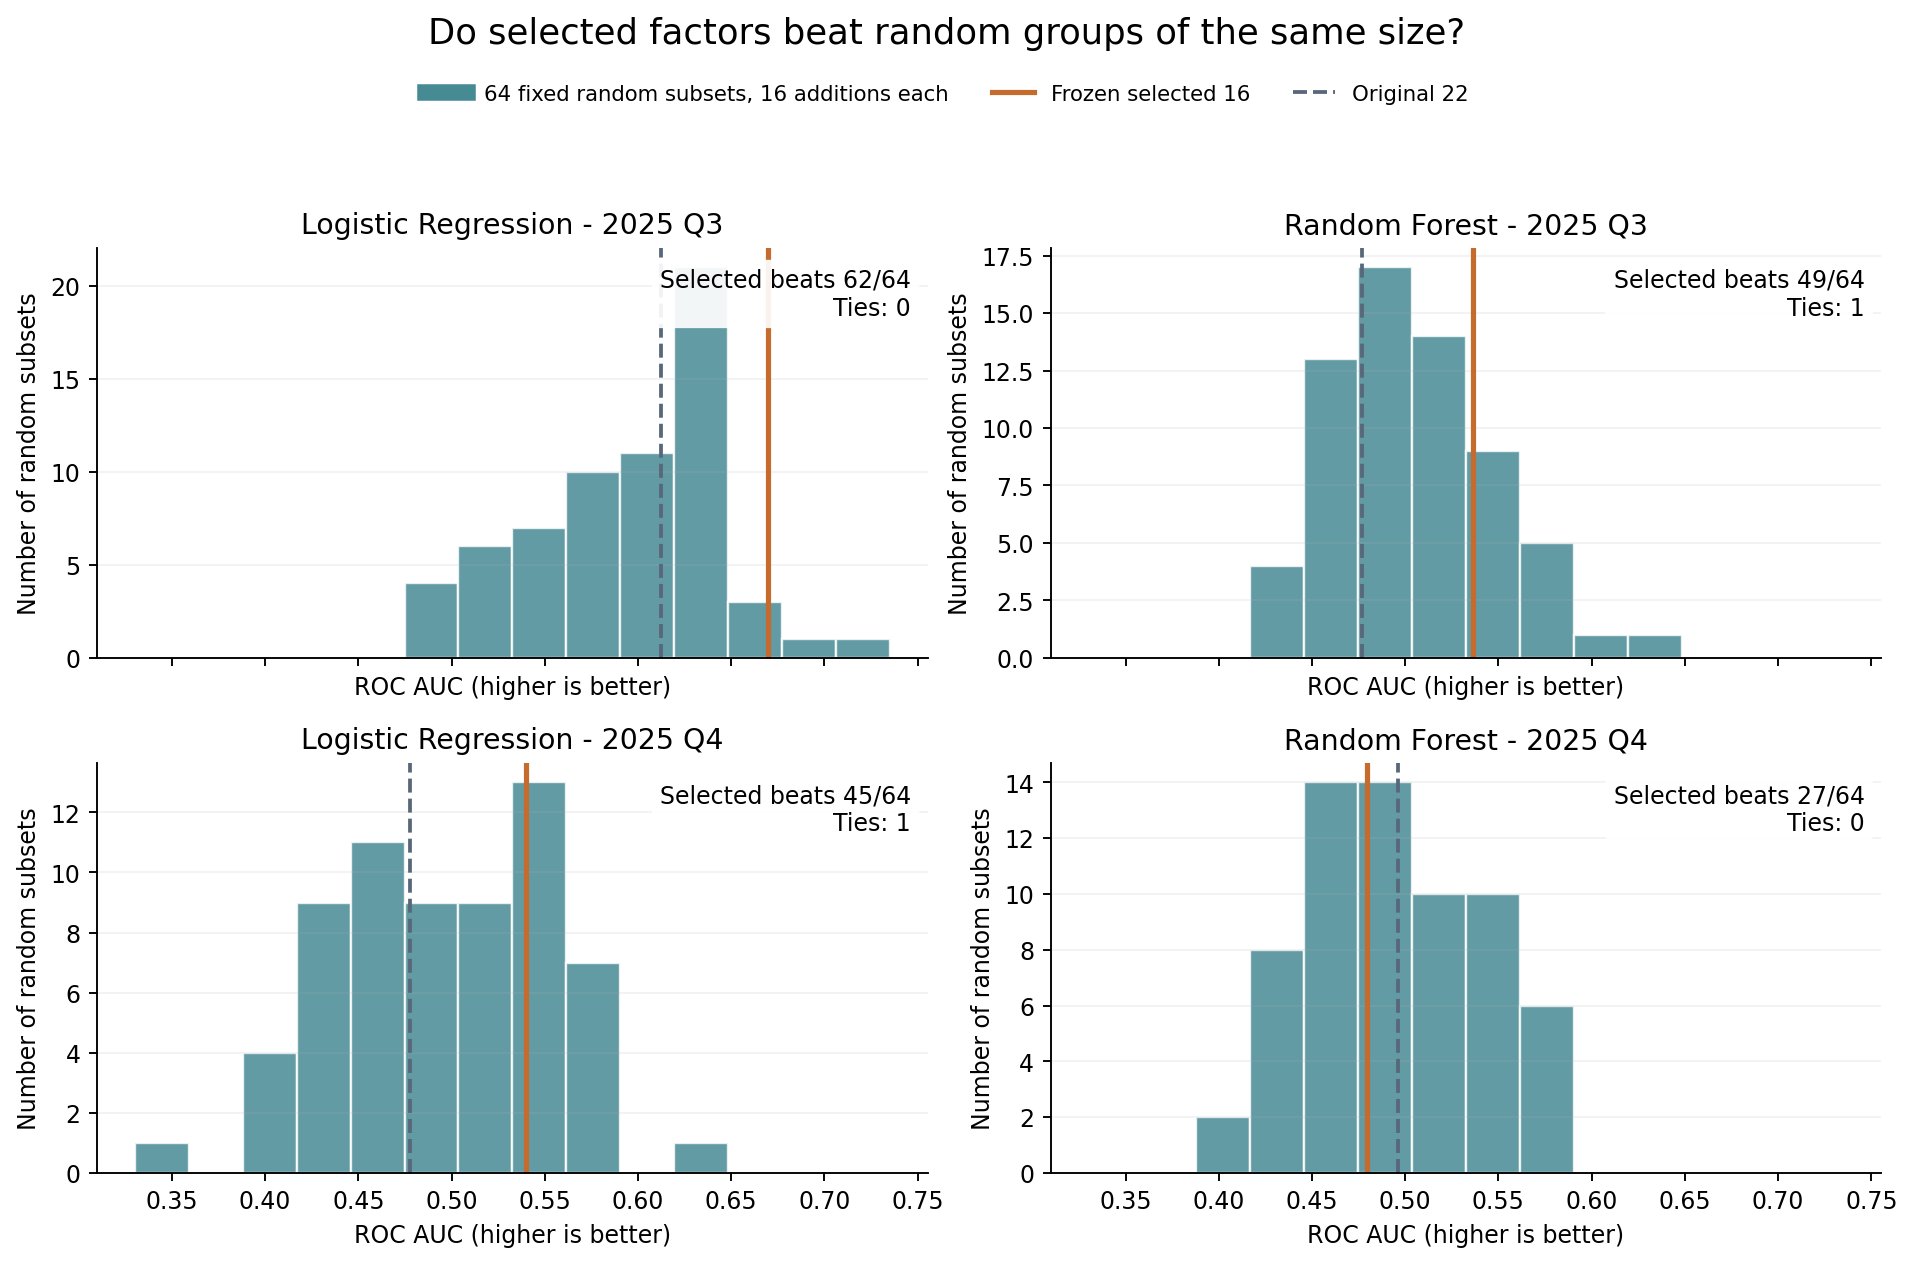

In [5]:
comparison = tables['random_comparison']
view = comparison[['period','model','selected16_AUC','random16_mean',
                   'random_below_selected','random_equal_selected','random_above_selected']].copy()
view['model'] = view.model.map(report.MODEL_NAMES)
view.columns = ['Window','Model','Selected AUC','Random mean AUC','Random groups below','Ties','Random groups above']
show_table(view)
display(Image(filename=str(RESULTS / 'figures' / 'random_subset_comparison.png')))

**Read the figure:** the bars count the AUCs of 64 random groups. Orange marks the frozen selected group. The dashed line marks the original 22 inputs. A count such as 45/64 means the selected group scored above 45 of these fixed groups; it is not an accuracy or a significance level.

## Step 3: Remove one selected factor and refit

For each model, keep all original 22 inputs and remove one of its 16 additions. Fit the same model again with the remaining 15 additions. Repeat for every addition.

**Removal drop = full-16 AUC minus the AUC after deletion.** Positive means deletion lowered the score. Negative means deletion raised it. This checks sensitivity to a factor within this group. It is not causal importance; correlated inputs and RF refitting also affect the result. The deletion results do not choose a new final subset.

In [6]:
deletion_configs = []
for model, selected_names in plan['selected_factors'].items():
    for removed in selected_names:
        remaining = [name for name in selected_names if name != removed]
        assert len(remaining) == 15
        deletion_configs.append({'model': model, 'removed': removed, 'remaining': remaining})
assert len(deletion_configs) == 32
print('32 model-specific deletion configurations, each evaluated in both windows.')

def show_deletions(model):
    frame = tables['deletion_stability'].loc[tables['deletion_stability'].model.eq(model)].copy()
    frame = frame[['position','removed_factor','2025_Q3','2025_Q4','pattern']]
    frame.columns = ['Position','Removed factor','Q3 removal drop','Q4 removal drop','Direction across windows']
    show_table(frame)
    display(Image(filename=str(RESULTS / 'figures' / f'deletion_{model}.png')))

32 model-specific deletion configurations, each evaluated in both windows.


Position,Removed factor,Q3 removal drop,Q4 removal drop,Direction across windows
1,r2_intraday_body_vs_overnight_move,0.00202,-0.00714,Mixed or zero change
2,r2_prior_body_share_of_range,0.03838,0.02347,Deletion lowers AUC in both windows
3,r2_signed_overnight_gap_range_share,0.00000,-0.00102,Mixed or zero change
4,r2_peer_sign_consensus,-0.00303,0.05204,Mixed or zero change
5,r2_prior_close_range_position,0.00606,0.01122,Deletion lowers AUC in both windows
6,r2_prior_body_signed_range_fraction,0.00202,0.01939,Deletion lowers AUC in both windows
7,r2_volume_acceleration_body_5d,-0.02020,-0.00408,Deletion raises AUC in both windows
8,r2_adjacent_return_sign_persistence_3d,0.00707,0.01122,Deletion lowers AUC in both windows
9,r2_close_location_range_change,-0.00404,0.00408,Mixed or zero change
10,r2_peer_return_sign_spread_3d,0.02727,-0.03673,Mixed or zero change


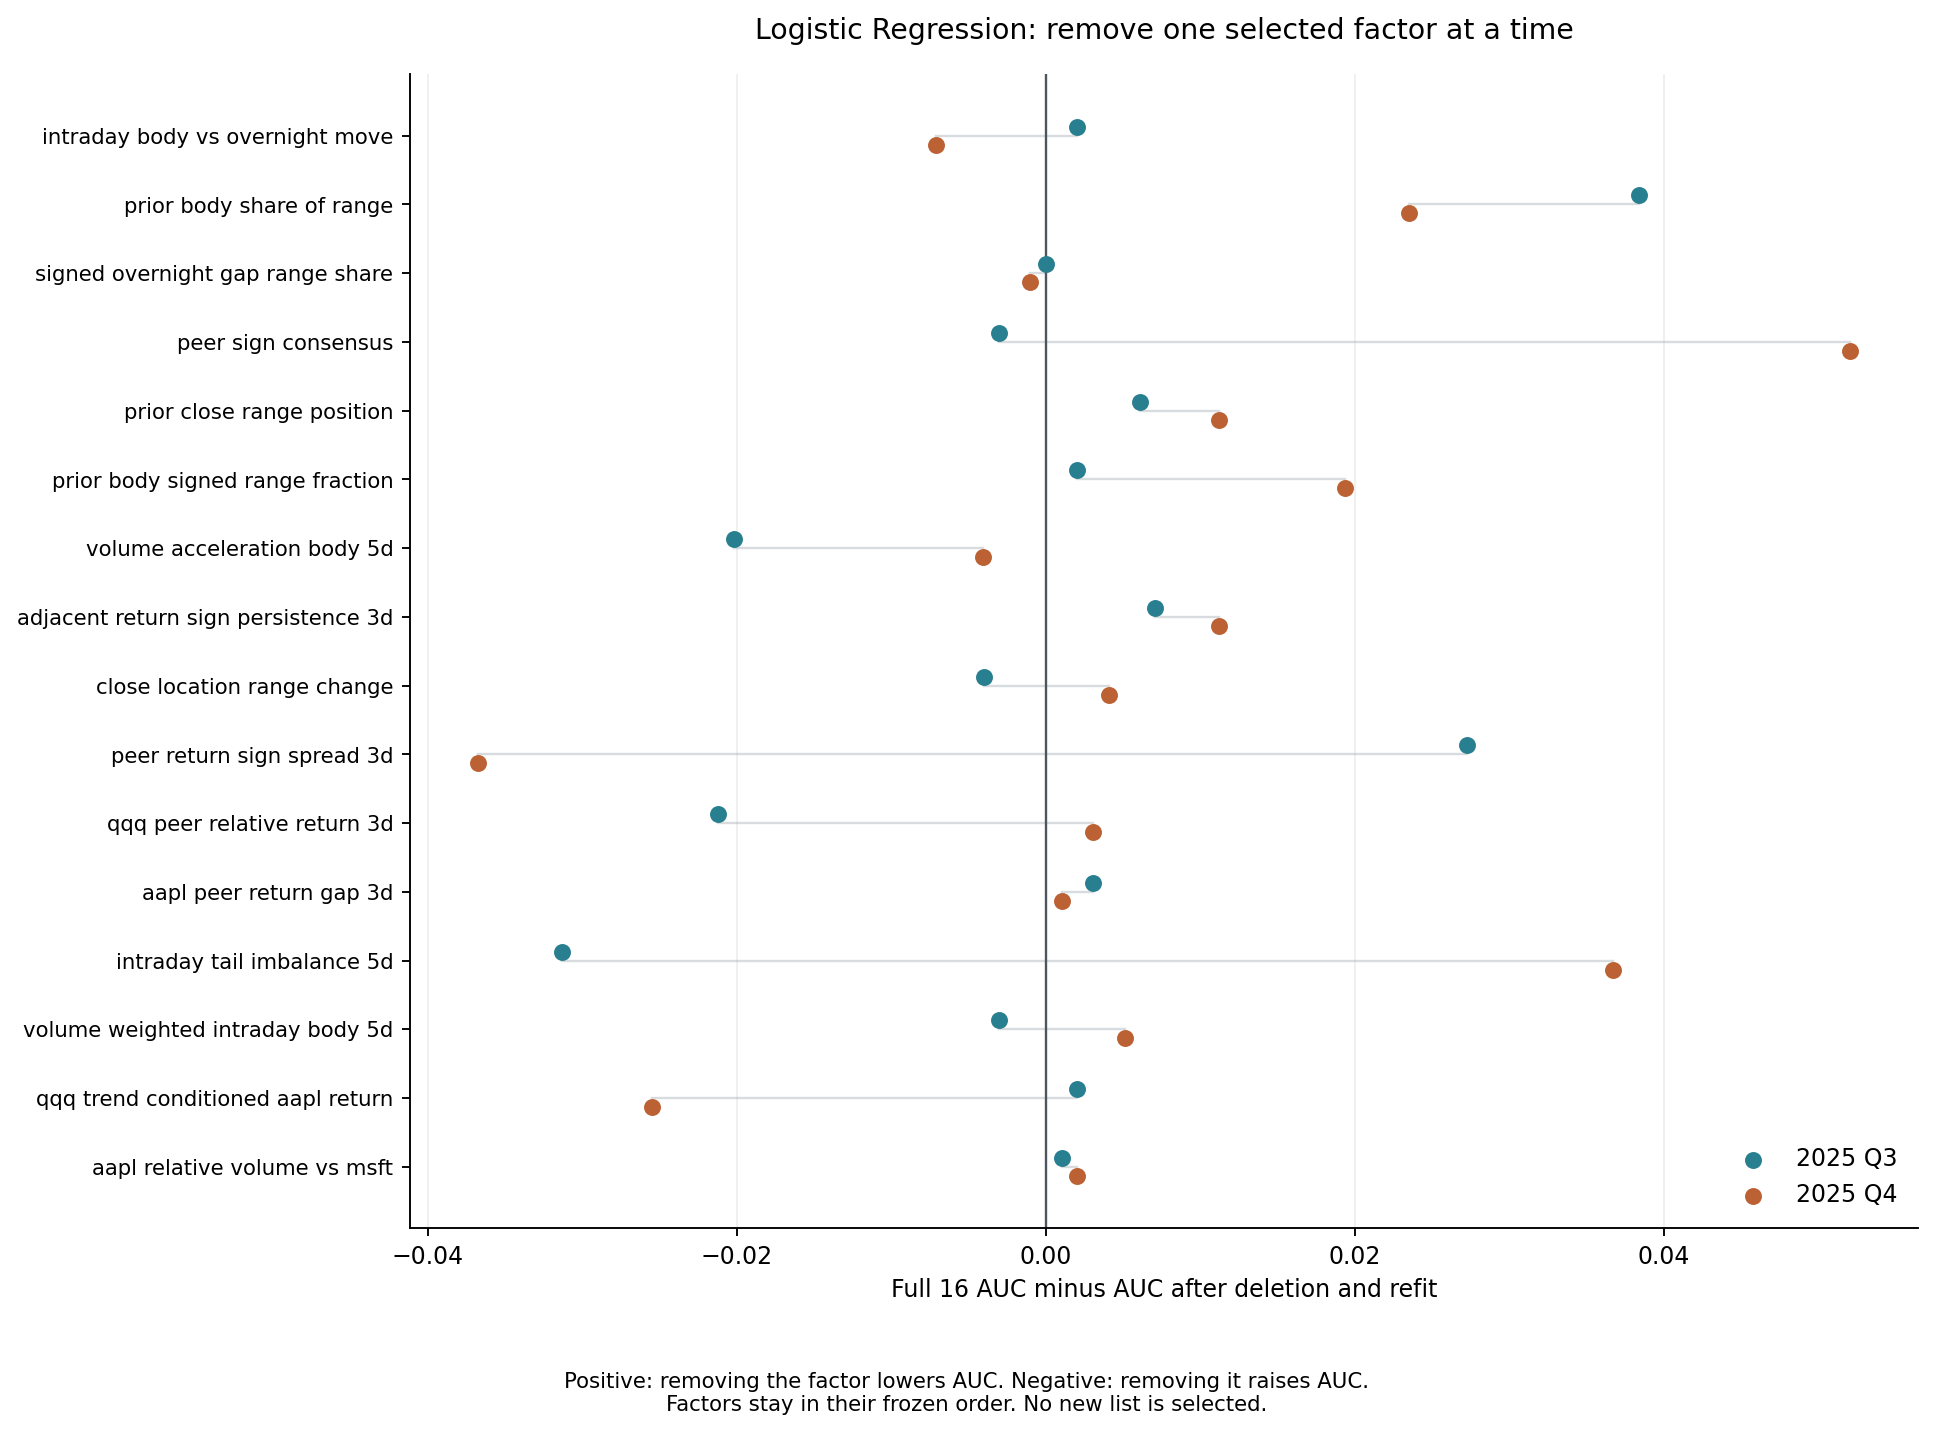

In [7]:
show_deletions('LR')

Position,Removed factor,Q3 removal drop,Q4 removal drop,Direction across windows
1,r2_volume_weighted_range_position_10d,0.00909,0.02143,Deletion lowers AUC in both windows
2,r2_peer_relative_volume_nvidia,-0.01111,0.01837,Mixed or zero change
3,r2_relative_dollar_activity_short_long,-0.05859,-0.03061,Deletion raises AUC in both windows
4,r2_nonoverlapping_three_day_return_change,0.02222,0.03469,Deletion lowers AUC in both windows
5,r2_volume_regime_gap,0.01111,0.03776,Deletion lowers AUC in both windows
6,r2_prior_close_range_position,0.01212,0.04286,Deletion lowers AUC in both windows
7,r2_prior_range_width_scaled,0.00707,0.03367,Deletion lowers AUC in both windows
8,r2_prior_close_to_low_scaled,0.01212,0.01429,Deletion lowers AUC in both windows
9,r2_aapl_peer_return_gap_3d,0.02424,0.02347,Deletion lowers AUC in both windows
10,r2_prior_body_share_of_range,0.03232,0.03469,Deletion lowers AUC in both windows


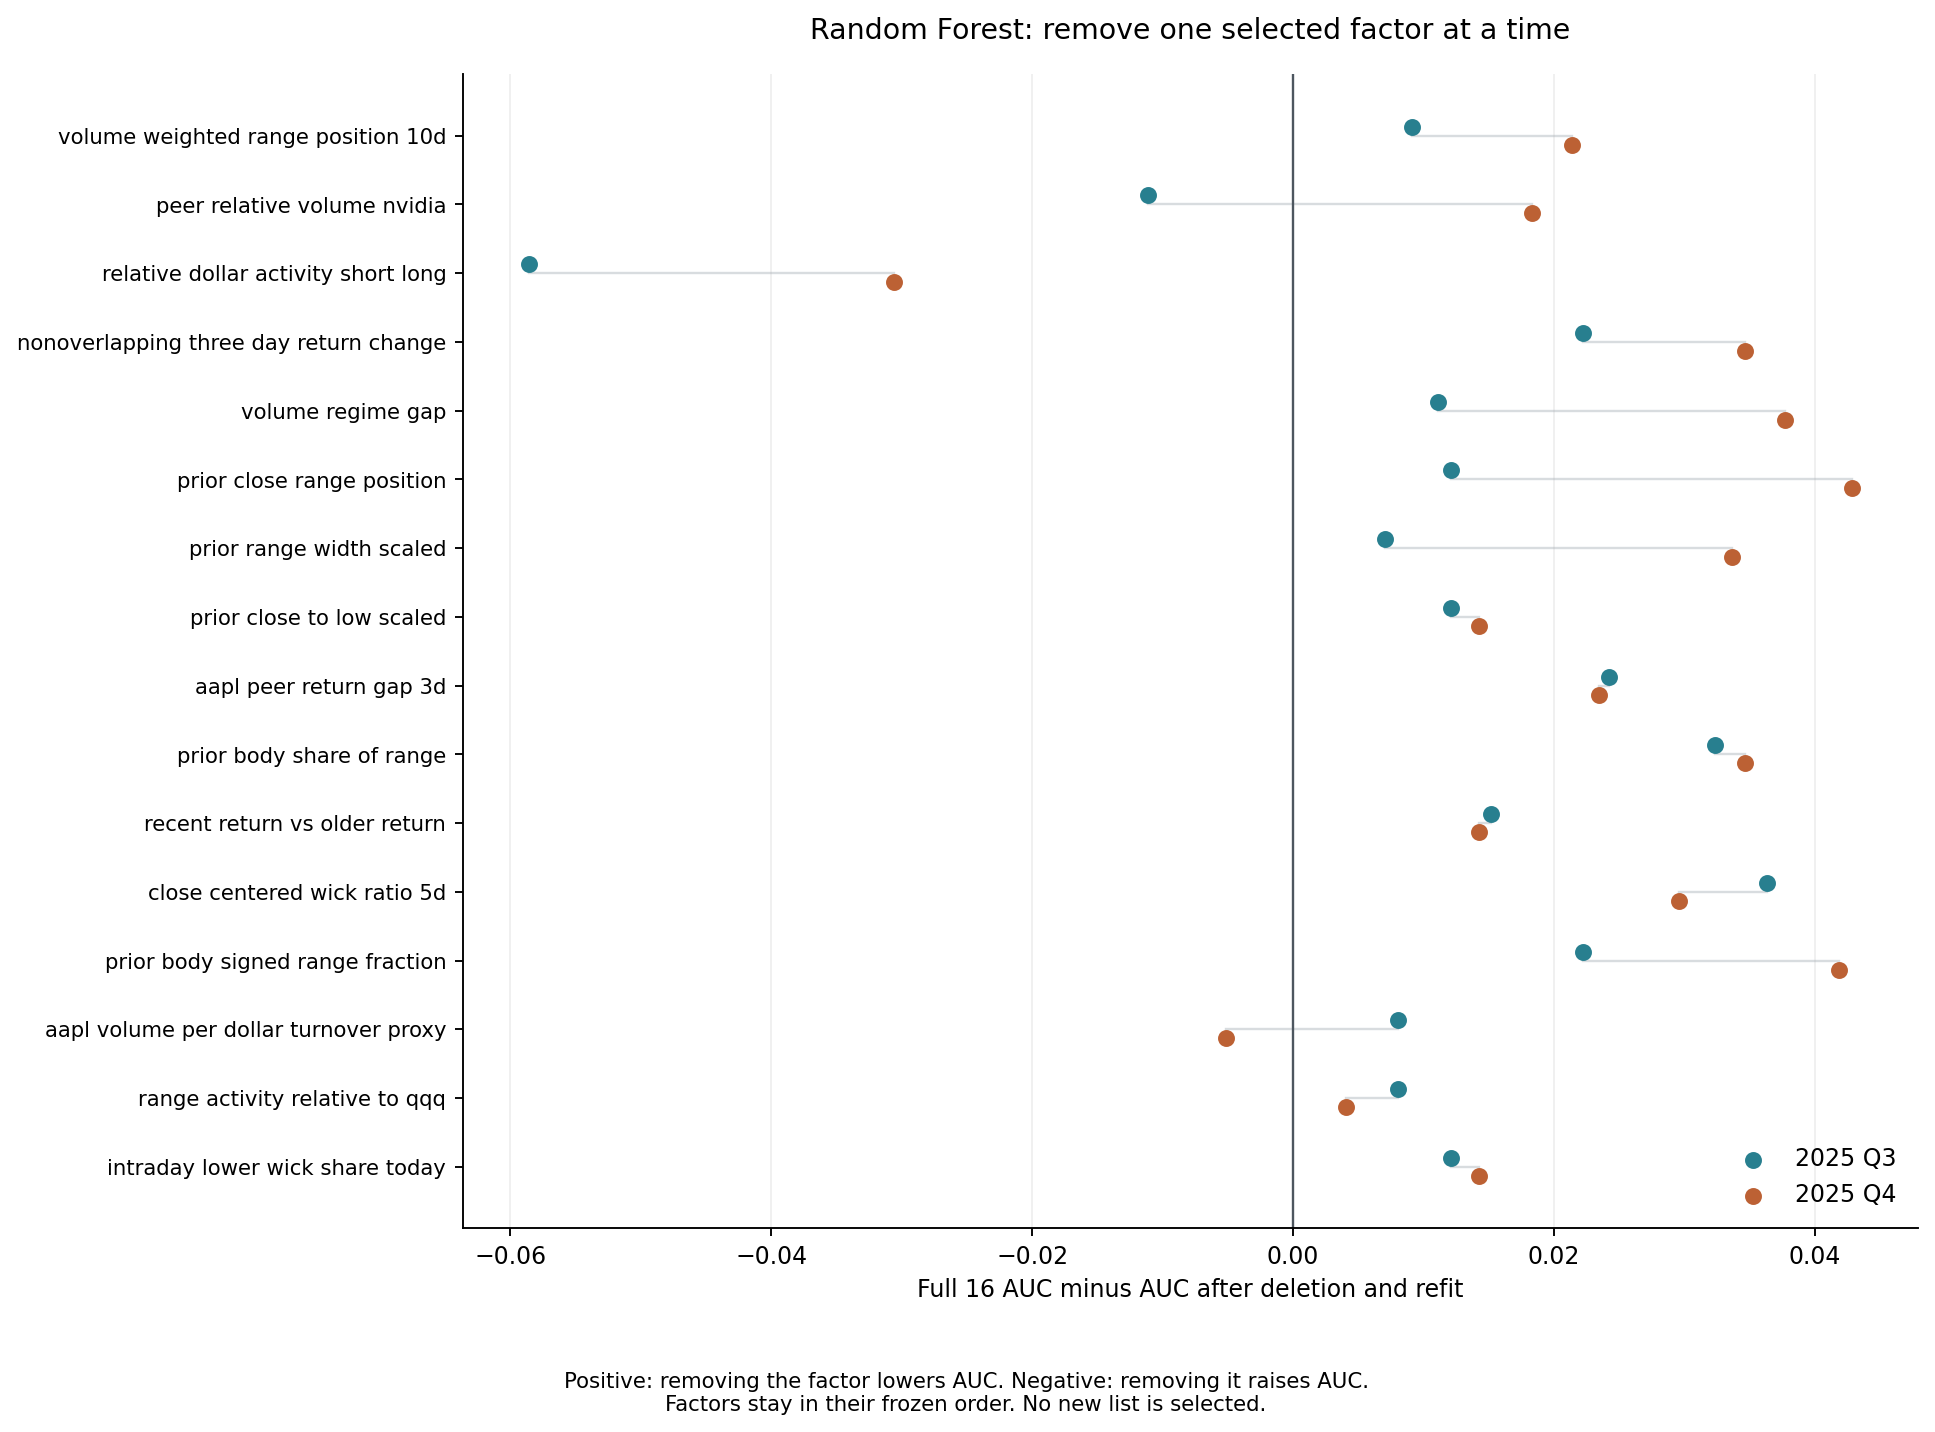

In [8]:
show_deletions('RF')

In [9]:
patterns = ['Deletion lowers AUC in both windows', 'Deletion raises AUC in both windows', 'Mixed or zero change']
counts = (tables['deletion_stability'].groupby(['model','pattern']).size()
          .unstack(fill_value=0).reindex(columns=patterns, fill_value=0).reset_index())
counts['model'] = counts.model.map(report.MODEL_NAMES)
show_table(counts.rename(columns={'model':'Model'}))

pattern,Model,Deletion lowers AUC in both windows,Deletion raises AUC in both windows,Mixed or zero change
,Logistic Regression,6,1,9
,Random Forest,13,1,2


## Step 4: Historical consistency and uncertainty

The same frozen selected lists are carried across Q3 and Q4. The random and deletion experiments use the same training data for both windows. Two matching signs do not establish a reliable future effect.

For the selected-versus-random comparison, a paired circular block bootstrap resamples five-day blocks 2,000 times. Every compared AUC is recalculated on each common resample. The interval is conditional on the existing fitted models, selections and 64 random groups. It does not account for the full mining process or earlier historical inspection. Detailed intervals for all 64 deletion/window cases are saved in `results/deletion_results.csv`. Deletion intervals are pointwise and are not corrected for testing multiple factors.

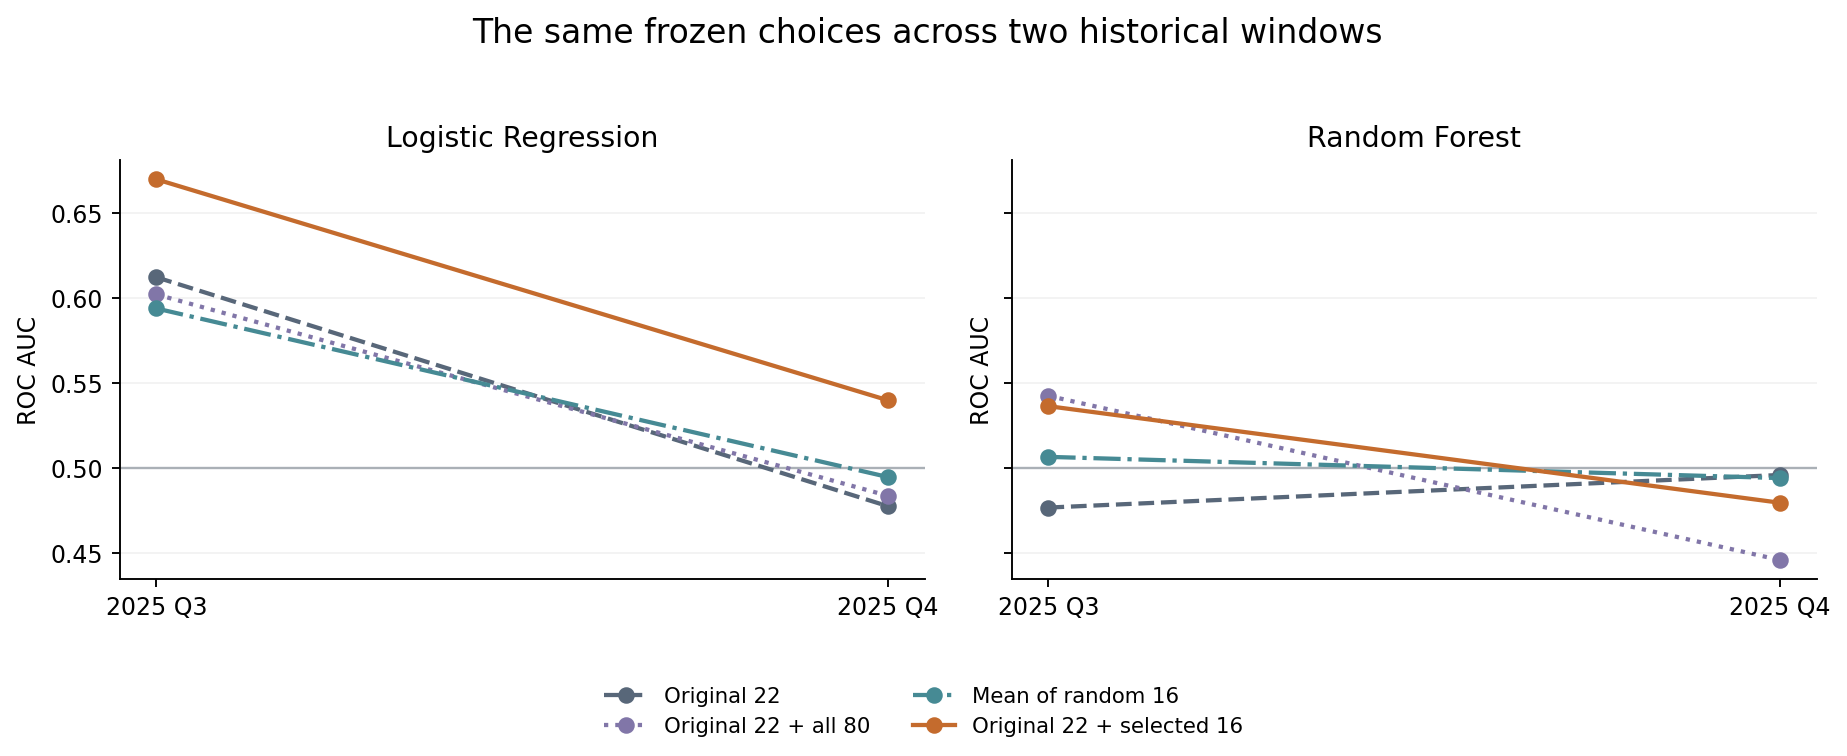

Window,Model,Selected minus random mean,95% low,95% high,Includes zero
2025_Q3,Logistic Regression,0.07592,-0.05703,0.20634,True
2025_Q3,Random Forest,0.02980,-0.07526,0.11802,True
2025_Q4,Logistic Regression,0.04511,-0.04174,0.14672,True
2025_Q4,Random Forest,-0.01451,-0.13236,0.09608,True


In [10]:
display(Image(filename=str(RESULTS / 'figures' / 'two_window_comparison.png')))
uncertainty = comparison[['period','model','selected_minus_random_mean',
                          'conditional_95_low','conditional_95_high','conditional_interval_includes_zero']].copy()
uncertainty['model'] = uncertainty.model.map(report.MODEL_NAMES)
uncertainty.columns = ['Window','Model','Selected minus random mean','95% low','95% high','Includes zero']
show_table(uncertainty)

**Measured conclusion:** LR scores above the random-group mean in both windows. RF scores above it in Q3 and below it in Q4. All four selected-minus-random-mean intervals include zero. The experiment does not establish reliable improvement on new data. The deletion results identify sensitivities worth understanding, rather than a newly validated factor list.

## Step 5: Completed verification

The checks below cover the frozen inputs, the previous results, every new saved prediction group, RF seed averages, exact one-factor deletions and factor date behavior. A separate uncached replay refitted every estimator and reproduced the saved probabilities and metrics. Passing implementation checks does not establish trading profitability.

In [11]:
checks = tables['verification']
assert checks.passed.all()
assert study.source_hashes() == plan['source_hashes']
show_table(checks.rename(columns={'check':'Completed check','passed':'Passed','details':'Evidence'}))

replay = study.read(RESULTS / 'REPLAY_VERIFICATION.json')
assert replay['passed']
show_table(pd.DataFrame([
    ['Fresh model configurations', replay['fresh_configurations']],
    ['Fresh fitted estimators', replay['fresh_estimators']],
    ['Reproduced model/seed/window scores', replay['metrics_groups']],
    ['Reproduced dated prediction rows', replay['prediction_rows']],
    ['Maximum allowed numeric difference', f"{replay['maximum_allowed_numeric_difference']:.0e}"],
], columns=['Independent replay', 'Result']))
print('All displayed checks and the separate fresh-model replay passed.')

Completed check,Passed,Evidence
"Original pool, selections, model sources and saved results remain byte-identical",True,80 formulas; 78 eligible; 16 frozen additions for each model
"Fresh baseline, all80 and selected16 predictions reproduce the previous experiment",True,12 model/window groups; maximum probability error 2.78e-16
All existing LR random-subset scores reproduce,True,128 comparisons; maximum AUC error 5.55e-17; reported as prior work
Independent rank AUC and balanced accuracy reproduce every saved prediction group,True,830 groups; shared dated labels in each window
"RF probabilities equal the mean of seeds 0, 1 and 2",True,166 configuration/window ensembles
Every deletion removes exactly one addition and keeps all original 22 inputs,True,"32 model-specific deletions, each evaluated in both windows"
Factor values match the saved source and remain unchanged when future prices change,True,All 80 formulas; 2025 Q1-Q2 prefix; clipping boundaries saved separately
All planned random and deletion configurations completed,True,"166 configurations; 332 fitted estimators; two fixed 63-row windows; 52,290 dated predictions including RF seeds"


Independent replay,Result
Fresh model configurations,166
Fresh fitted estimators,332
Reproduced model/seed/window scores,830
Reproduced dated prediction rows,52290
Maximum allowed numeric difference,1e-14


All displayed checks and the separate fresh-model replay passed.


**Contribution:** matched random controls for RF, deletion experiments for both models, and a transparent comparison across two historical windows, using the earlier frozen pool and selections. Team data and baseline model settings are reused. ChatGPT assisted implementation and analysis. Full sources, results, all factor names and the fixed plan are included in the project.